# Assignment 4 - Naive Bayes
Classify disaster tweets: `0` = non-disaster, `1` = disaster.

In [10]:
import re
import string
from html import unescape

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

## 1. Load and split the dataset
Read dataset and split 10% for testing.

In [11]:
df = pd.read_csv('train.csv')
display(df.head())

print('Dataset shape:', df.shape)
display(df.isna().sum().rename('Missing values'))

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1


Dataset shape: (7613, 5)


,Missing values
id,0
keyword,61
location,2533
text,0
target,0


,train,test
target,,
0,3907,435
1,2944,327


,train,test
target,,
0,57.03,57.09
1,42.97,42.91


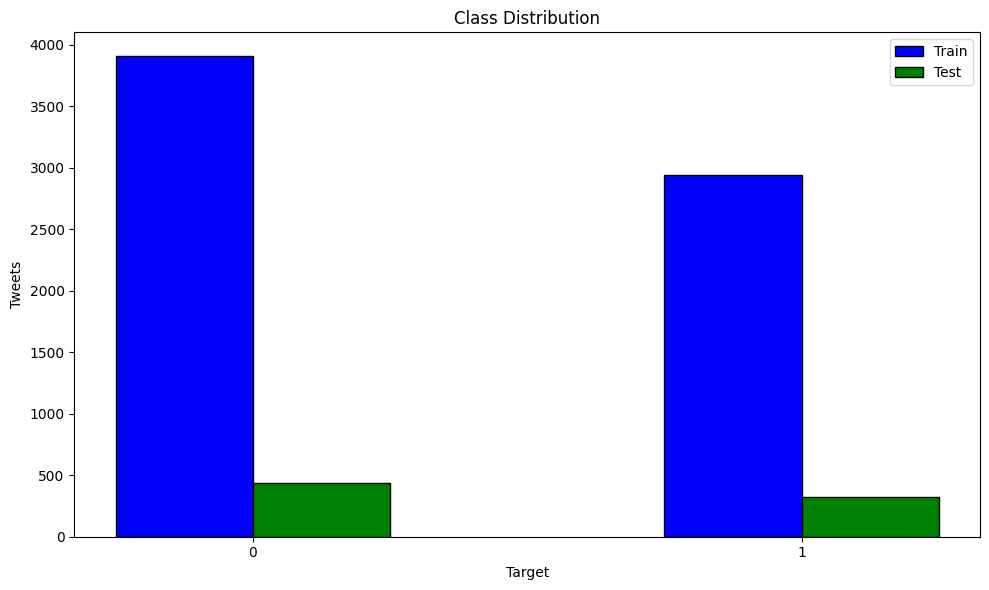

In [12]:
train,test = train_test_split(
    df, test_size=0.1, stratify=df['target'], random_state=0
)
train = train.copy()
test = test.copy()

y_train_counts = train['target'].value_counts().sort_index()
y_test_counts = test['target'].value_counts().sort_index()

counts = pd.DataFrame({'train': y_train_counts, 'test': y_test_counts})

display(counts)
display((counts/counts.sum()*100).round(2))

x = np.arange(len(y_train_counts))

width = 0.25
plt.figure(figsize=(10, 6))
plt.bar(x-width/2, y_train_counts, width, label='Train', color='blue', edgecolor='black')
plt.bar(x+width/2, y_test_counts, width, label='Test', color='green', edgecolor='black')

plt.title('Class Distribution')
plt.xlabel('Target')
plt.ylabel('Tweets')

plt.xticks(x, y_train_counts.index)
plt.legend()
plt.tight_layout()

plt.show()

The dataset is not balanced because there are `57.09%` non-disaster and `42.97%` disaster tweets.

## 2. Prepare/edit data

Replace `%20` with spaces in keywords before combining `keyword` and `text`.

In [13]:
dcols = ['id', 'location']
train = train.drop(columns=dcols).fillna('null')
test = test.drop(columns=dcols).fillna('null')

for data in [train, test]:
    data['keyword'] = data['keyword'].str.replace('%20', ' ', regex=False)
    data['inputs'] = data['keyword'] + ' ' + data['text']

display(train.head())

,keyword,text,target,inputs
6669,threat,Meek Mill responds to DrakeÛªs OVO Fest set w...,1,threat Meek Mill responds to DrakeÛªs OVO Fes...
3940,flood,survived the plague\nfloated the flood\njust p...,0,flood survived the plague\nfloated the flood\n...
7217,weapons,#Kick Hendrixonfire @'=BLACKCATS= | BIG NOOB ...,0,weapons #Kick Hendrixonfire @'=BLACKCATS= | B...
2234,deluge,Vince McMahon once again a billionaire: I reme...,0,deluge Vince McMahon once again a billionaire:...
4233,hazardous,Is it possible to sneak into a hospital so I c...,0,hazardous Is it possible to sneak into a hospi...


## 3. Clean input tweets

- Remove Unicode characters: removes emojis and non-ascii characters from the tweets.
- Replace URL: replaces urls with `url` and removes `#`.
- Unescape html entities: converts `&amp;`, `&gt;` and `&lt;` to `&`, `>`, `<`.
- Replace user at: replaces the with `atUser` to reduce irrelevant information
- Remove symbols and punctuation: removes punctuation that is unnecessary for the word processing we are planning to do.
- Lower case everything: gives words with capitalized characters like `Word` and `word` the same representation.


In [14]:
def removeUnicode(text):
    """ Removes unicode strings like "\u002c" and "x96" """
    text = re.sub(r'(\\u[0-9A-Fa-f]+)',r'', text)
    text = re.sub(r'[^\x00-\x7f]',r'',text)
    return text

def replaceURL(text):
    """ Replaces url address with "url" """
    text = re.sub('((www\.[^\s]+)|(https?://[^\s]+))','url',text)
    text = re.sub(r'#([^\s]+)', r'\1', text)
    return text

def replaceAtUser(text):
    """ Replaces "@user" with "atUser" """
    text = re.sub('@[^\s]+','atUser',text)
    return text

<>:9: SyntaxWarning: invalid escape sequence '\.'
<>:15: SyntaxWarning: invalid escape sequence '\s'
<>:9: SyntaxWarning: invalid escape sequence '\.'
<>:15: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_2130/1644850876.py:9: SyntaxWarning: invalid escape sequence '\.'
  text = re.sub('((www\.[^\s]+)|(https?://[^\s]+))','url',text)
/tmp/ipykernel_2130/1644850876.py:15: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub('@[^\s]+','atUser',text)


In [15]:
for data in [train, test]:
    data['inputs'] = data['inputs'].apply(removeUnicode)
    data['inputs'] = data['inputs'].apply(replaceURL)
    data['inputs'] = data['inputs'].apply(unescape)
    data['inputs'] = data['inputs'].apply(replaceAtUser)
    data['inputs'] = data['inputs'].str.translate(str.maketrans('', '', string.punctuation)) # Technique 7: remove punctuation
    data['inputs'] = data['inputs'].str.lower()

display(train[['text', 'inputs']].head(), )

,text,inputs
6669,Meek Mill responds to DrakeÛªs OVO Fest set w...,threat meek mill responds to drakes ovo fest s...
3940,survived the plague\nfloated the flood\njust p...,flood survived the plague\nfloated the flood\n...
7217,#Kick Hendrixonfire @'=BLACKCATS= | BIG NOOB ...,weapons kick hendrixonfire atuser big noob c...
2234,Vince McMahon once again a billionaire: I reme...,deluge vince mcmahon once again a billionaire ...
4233,Is it possible to sneak into a hospital so I c...,hazardous is it possible to sneak into a hospi...


## 4. Convert to numpy arrays

In [16]:
inputs_train = train['inputs'].to_numpy()
inputs_test = test['inputs'].to_numpy()

y_train = train['target'].to_numpy()
y_test = test['target'].to_numpy()

print('Train: ', inputs_train.shape,y_train.shape)
print('Test: ', inputs_test.shape,y_test.shape)

Train:  (6851,) (6851,)
Test:  (762,) (762,)


## 5. TF-IDF vectorizer

In [17]:
tfidf = TfidfVectorizer(dtype=np.float32)

x_train = tfidf.fit_transform(inputs_train)
x_test = tfidf.transform(inputs_test)

print('Train TF-IDF: ', x_train.shape)
print('Test TF-IDF: ', x_test.shape)


Train TF-IDF:  (6851, 14656)
Test TF-IDF:  (762, 14656)


## 6. Train Gaussian NB

In [18]:
model = GaussianNB()
model.fit(x_train.toarray(), y_train)
y_pred = model.predict(x_test.toarray())

test_results = pd.DataFrame([{
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
    'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
    'F1': f1_score(y_test, y_pred, average='macro', zero_division=0)
}], index=['Test'])

test_results = test_results.round(4)
display(test_results)


,Accuracy,Precision,Recall,F1
Test,0.626,0.6557,0.6477,0.6246


The model correctly classifies only `62.6%` of the test tweets. The precision is `65.57%` while recall is `64.77%` and F1 is `62.46%`.